<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Accuracy: 0.73
              precision    recall  f1-score   support

    Rejected       0.70      0.76      0.73        97
    Approved       0.76      0.70      0.73       103

    accuracy                           0.73       200
   macro avg       0.73      0.73      0.73       200
weighted avg       0.73      0.73      0.73       200



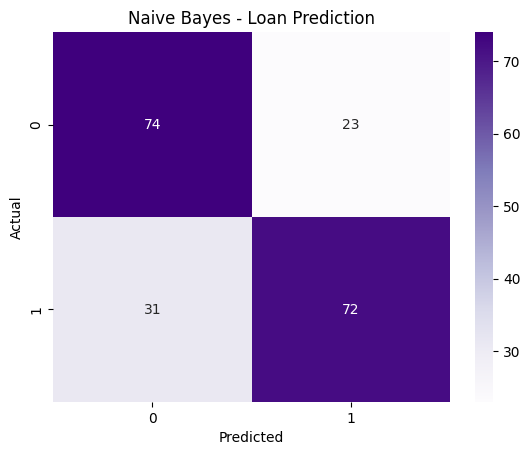

Loan: Approved | P(approve) = 0.798


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rng = np.random.default_rng(42)
n = 1000
df = pd.DataFrame({
    "Age": rng.integers(21, 65, n),
    "Income": rng.normal(50000, 15000, n).clip(15000),
    "LoanAmount": rng.normal(150000, 60000, n).clip(20000),
    "CreditScore": rng.integers(300, 850, n),
    "Employment": rng.choice(["Salaried", "Self-Employed", "Unemployed"], n, p=[0.6, 0.3, 0.1]),
    "Married": rng.choice(["Yes", "No"], n),
})
score = (df.CreditScore/850)*0.5 + (df.Income/df.LoanAmount)*0.8 + (df.Employment != "Unemployed")*0.3
df["Loan_Status"] = (score + rng.normal(0, 0.15, n) > score.median()).astype(int)

for c in ["Employment", "Married"]:
    df[c] = LabelEncoder().fit_transform(df[c])

X = df.drop("Loan_Status", axis=1); y = df["Loan_Status"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

nb = GaussianNB().fit(X_train, y_train)
pred = nb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred, target_names=["Rejected", "Approved"]))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Purples")
plt.title("Naive Bayes - Loan Prediction"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

# New applicant: Age, Income, LoanAmount, CreditScore, Employment(0-2), Married(0/1)
new = pd.DataFrame([[35, 60000, 120000, 720, 2, 1]], columns=X.columns)
print("Loan:", "Approved" if nb.predict(new)[0] == 1 else "Rejected",
      "| P(approve) =", round(nb.predict_proba(new)[0][1], 3))